# Tổng hợp phát hiện — Validation: thứ tự EASE là dấu vết của nhân tố thị trường (20 mã)

Gom các phát hiện chính từ `01_market_factor`, `02_permutation_tests`, `03_time_stability`, `04_calibrated_simulation`.

| # | Phát hiện | Hệ quả |
|---|---|---|
| 1 | Thị trường dẫn ở đuôi sập: $\hat\Gamma^-_{\text{VNI}\to i}$ tới 0,99, lớn hơn chiều ngược lại ở 16/20 mã | Nguồn sốc chung có chiều |
| 2 | Thứ tự EASE ≈ thứ tự hệ số tải thị trường: Spearman ρ = 0,91 (p = 2·10⁻⁸), lặp lại qua thời gian (ρ 0,67–0,82) | Thứ tự không phải lan truyền |
| 3 | Loại thị trường: cặp phụ thuộc đuôi giảm từ 237/380 xuống 15/380 (max-T, FWER 5%) | Phụ thuộc đuôi chủ yếu do thị trường |
| 4 | Mô hình một nhân tố không nhân quả tái hiện thứ tự (ρ = 0,91) nhưng thiếu phụ thuộc ngành (59 cặp vượt dải) | Còn nhân tố ngành |
| 5 | EASE chỉ thấy cạnh ≥ 0,2–0,3 giữa mã tải tương đương; kiểm định hoán đổi sai loại I tới 54% | Giới hạn phương pháp |

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "validation"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

from scipy import stats
TAB = ROOT / "report" / "table"
def read(name, folder=FOLDER, **kw):
    path = TAB / folder / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Thiếu {path.relative_to(ROOT)} — chạy các notebook chi tiết của giai đoạn trước.")
    return pd.read_csv(path, encoding="utf-8-sig", **kw)
P = len(SYMBOLS); OFF = ~np.eye(P, dtype=bool)
SEC = np.array([U.SECTOR[s] for s in SYMBOLS])
def sector_blocks(M):
    """Trung bình hệ số theo khối ngành (ngành nguồn × ngành đích), bỏ đường chéo."""
    rows = [(SEC[i], SEC[j], M[i, j]) for i in range(P) for j in range(P) if i != j and not np.isnan(M[i, j])]
    d = pd.DataFrame(rows, columns=["nguon", "dich", "v"]).groupby(["nguon", "dich"]).v.mean().unstack()
    return d.reindex(index=U.SECTORS, columns=U.SECTORS)

## Phát hiện 1 — Thị trường là nguồn sốc đuôi có chiều

**Tính gì:** $\hat\Gamma^-_{\text{VNI}\to i}$ và $\hat\Gamma^-_{i\to\text{VNI}}$ (đuôi sập) cho 20 mã. Nếu VN-Index (lợi suất lọc GARCH) là nguyên nhân thì chiều VNI → mã → 1 và lớn hơn chiều ngược lại.

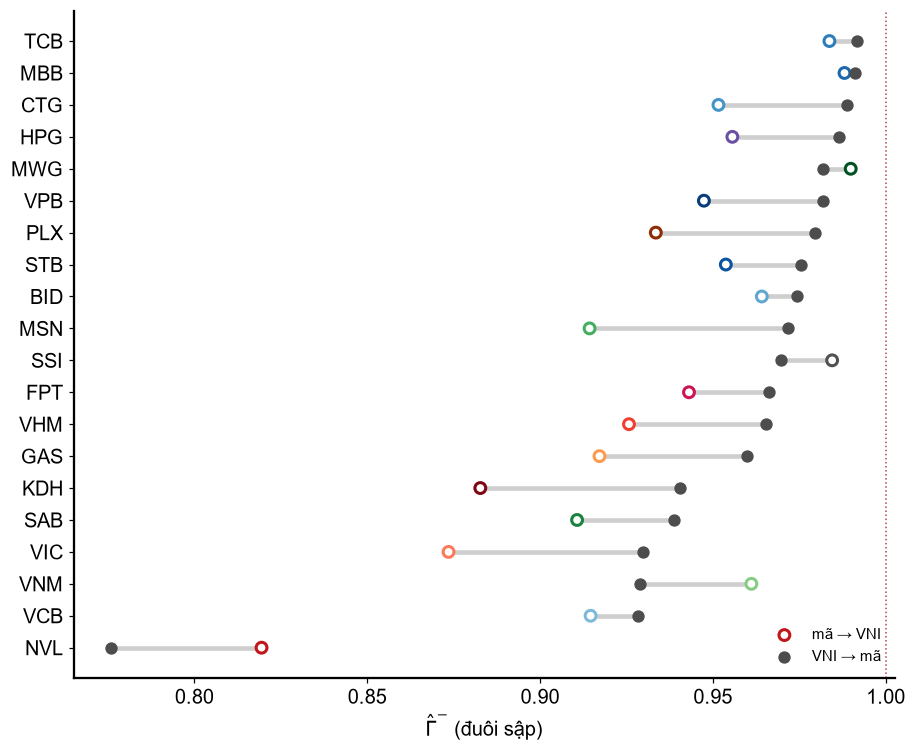

VNI→mã > mã→VNI ở 16/20 mã


In [2]:
mk = read("01_market_tail_coef", index_col=0).loc[SYMBOLS]
order = mk["Γ⁻ VNI→mã"].sort_values().index
fig, ax = plt.subplots(figsize=(8.5, 7))
y = np.arange(P)
ax.hlines(y, mk.loc[order, "Γ⁻ mã→VNI"], mk.loc[order, "Γ⁻ VNI→mã"], color=PAL["neutral"], lw=3)
ax.scatter(mk.loc[order, "Γ⁻ mã→VNI"], y, color=[COL[s] for s in order], s=50, facecolors="white", linewidths=2, zorder=3, label="mã → VNI")
ax.scatter(mk.loc[order, "Γ⁻ VNI→mã"], y, color=PAL["gray_dark"], s=50, zorder=3, label="VNI → mã")
ax.axvline(1, color=PAL["red_strong"], ls=":", lw=1); ax.set_yticks(y, order); ax.set_xlabel(r"$\hat\Gamma^{-}$ (đuôi sập)"); ax.legend(fontsize=10, loc="lower right")
U.finalize_figure(fig, "finding_1_market_leads", folder=FOLDER); plt.show()
print(f"VNI→mã > mã→VNI ở {(mk['Γ⁻ VNI→mã'] > mk['Γ⁻ mã→VNI']).sum()}/{P} mã")

### Phân tích
- Với 6/7 ngân hàng (trừ VCB), HPG, GAS, PLX: $\hat\Gamma^-_{\text{VNI}\to i}$ 0,96–0,99 — khi thị trường sập, các mã này gần như chắc chắn cũng sập. Ngoại lệ: NVL (cả hai chiều ~0,8), VNM, MWG, SSI.
- VN-Index chứa chính các mã nên một phần là cơ học; thị trường leave-one-out (phát hiện 2–3) xác nhận vai trò của nhân tố chung.

## Phát hiện 2 — Thứ tự EASE gần như là thứ tự hệ số tải thị trường

**Tính gì:** $\hat\beta_i$ từ $z_{i,t} = a_i + \beta_i\bar z_{-i,t} + e_{i,t}$ (thị trường leave-one-out) so với vị trí trung bình EASE (bootstrap của Processing); và Spearman
giữa hai đại lượng trong từng cửa sổ trượt 750 phiên.

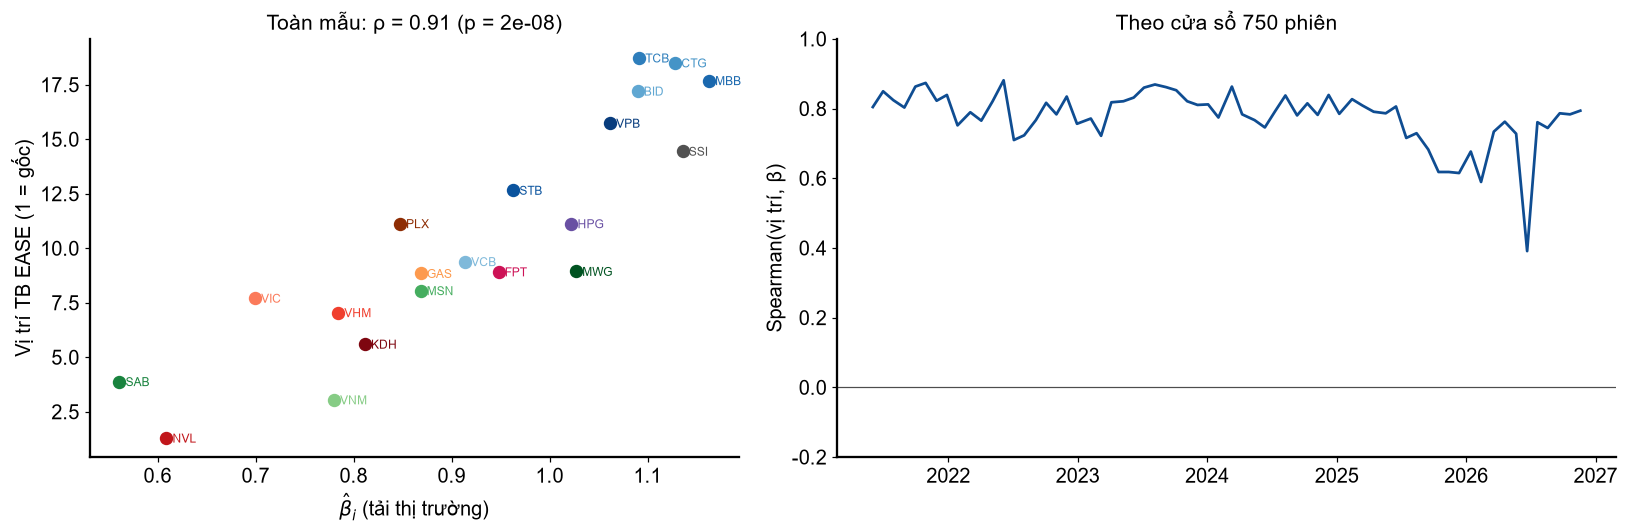

ρ theo cửa sổ: TB 0.78, min 0.39, max 0.88


In [3]:
b = read("01_beta_vs_position", index_col=0)
rho, pv = stats.spearmanr(b.beta_LOO, b.vi_tri_TB_bootstrap)
roll = read("03_rolling_ease", index_col=0, parse_dates=True)
posr = roll.filter(like="pos_").rename(columns=lambda c: c[4:])[SYMBOLS]; betr = roll.filter(like="beta_").rename(columns=lambda c: c[5:])[SYMBOLS]
rho_t = pd.Series([stats.spearmanr(posr.loc[t], betr.loc[t])[0] for t in posr.index], index=posr.index)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.2]})
for s in SYMBOLS:
    axes[0].scatter(b.loc[s, "beta_LOO"], b.loc[s, "vi_tri_TB_bootstrap"], color=COL[s], s=60, zorder=3)
    axes[0].annotate(s, (b.loc[s, "beta_LOO"], b.loc[s, "vi_tri_TB_bootstrap"]), xytext=(4, -3), textcoords="offset points", fontsize=8, color=COL[s])
axes[0].set_xlabel(r"$\hat\beta_i$ (tải thị trường)"); axes[0].set_ylabel("Vị trí TB EASE (1 = gốc)"); axes[0].set_title(f"Toàn mẫu: ρ = {rho:.2f} (p = {pv:.0e})")
axes[1].plot(rho_t.index, rho_t.values, color=PAL["blue_main"], lw=1.8); axes[1].axhline(0, color=PAL["gray_dark"], lw=0.8)
axes[1].set_ylim(-0.2, 1); axes[1].set_ylabel("Spearman(vị trí, β)"); axes[1].set_title("Theo cửa sổ 750 phiên")
U.finalize_figure(fig, "finding_2_order_equals_beta", folder=FOLDER); plt.show()
print(f"ρ theo cửa sổ: TB {rho_t.mean():.2f}, min {rho_t.min():.2f}, max {rho_t.max():.2f}")

### Phân tích
- ρ = 0,91 trên toàn mẫu; theo cửa sổ ρ luôn dương và trung bình 0,78. Mã làm gốc thuộc 3 mã có $\hat\beta$ thấp nhất ở 86% cửa sổ.
- Mã tải thấp (SAB, NVL, VIC, VNM) ít bị thị trường kéo theo ở đuôi nên EASE đặt lên đầu; ngân hàng tải cao (MBB, CTG, TCB, BID) xuống cuối.

## Phát hiện 3 — Loại thị trường, phụ thuộc đuôi gần như biến mất

**Tính gì:** số cặp có $\hat\Psi$ vượt phân phối dưới $H_0$ độc lập (xáo trộn thời gian từng cột, $B = 500$) sau hiệu chỉnh **max-T** (Westfall & Young 1993, FWER 5%),
trên $z$ và trên phần dư $e$ đã loại thị trường LOO.

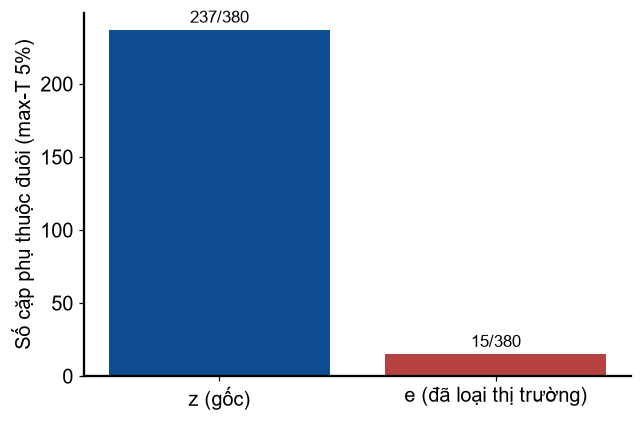

,psi_TB,so_cap_bac_bo_maxT5%
z,0.681,237.000
e,0.560,15.000


In [4]:
ind = read("02_independence_summary", index_col=0)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["z (gốc)", "e (đã loại thị trường)"], ind["so_cap_bac_bo_maxT5%"], color=[PAL["blue_main"], PAL["red_strong"]])
for i, v in enumerate(ind["so_cap_bac_bo_maxT5%"]):
    ax.text(i, v + 5, f"{int(v)}/380", ha="center", fontsize=11)
ax.set_ylabel("Số cặp phụ thuộc đuôi (max-T 5%)")
U.finalize_figure(fig, "finding_3_remove_market", folder=FOLDER); plt.show()
ind

### Phân tích
- 237/380 cặp phụ thuộc đuôi trên $z$; sau khi loại thị trường còn **15/380**. $\overline{\hat\Psi}$ giảm từ 0,68 xuống 0,56, phần còn lại tập trung trong cùng ngành.
- Kiểm định chiều (hoán đổi, $B$ = 4.999, FDR): **0/190** cặp có chiều trên $z$; trên $e$ chỉ 1 cặp (VCB → SSI, q = 0,04).

## Phát hiện 4 — Mô hình một nhân tố không nhân quả tái hiện thứ tự, nhưng thiếu phụ thuộc ngành

**Tính gì:** 500 bộ dữ liệu từ $X = \lambda F + \sqrt{1-\lambda^2}\,\varepsilon$ ($F$ ẩn, $t_\nu$, $\lambda$ khớp từ dữ liệu, **không có cạnh giữa các mã**). So vị trí EASE trung bình
dưới mô hình này với dữ liệu thật; và đếm các cặp $\hat\Psi$ thật nằm ngoài dải 90% mô phỏng.

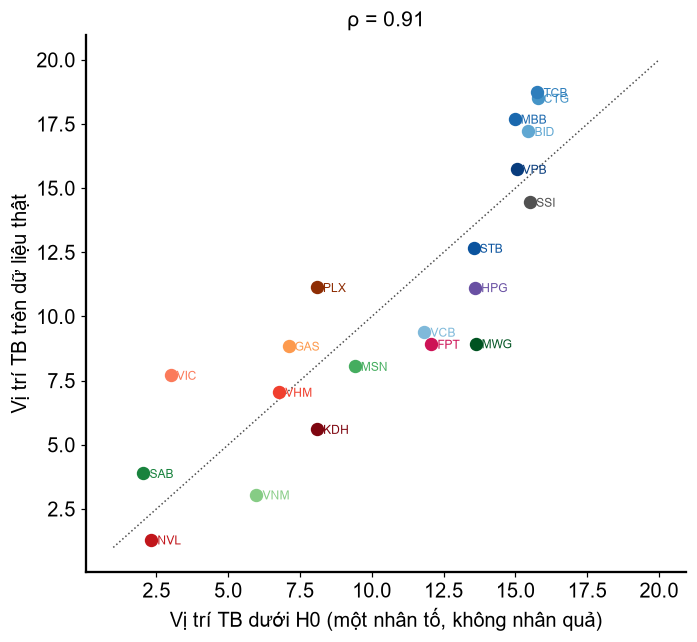

59 cặp vượt trên dải 90% của H0 (kỳ vọng ~19); lớn nhất:


,psi_obs,h0_q05,h0_median,h0_q95,chenh
cap,,,,,
VHM→VIC,0.842,0.497,0.585,0.659,0.257
VIC→VHM,0.763,0.477,0.559,0.634,0.205
PLX→GAS,0.799,0.528,0.615,0.697,0.184
GAS→PLX,0.790,0.524,0.608,0.681,0.182
VNM→SAB,0.733,0.489,0.573,0.643,0.160
GAS→VHM,0.759,0.517,0.600,0.679,0.160
GAS→HPG,0.768,0.541,0.619,0.692,0.149
VCB→BID,0.809,0.596,0.684,0.757,0.125


In [5]:
h = read("04_h0_vs_observed", index_col=0)
band = read("04_h0_psi_band", index_col=0)
out = band[(band.psi_obs > band.h0_q95)].assign(chenh=lambda d: d.psi_obs - d.h0_median).sort_values("chenh", ascending=False)
fig, ax = plt.subplots(figsize=(6.5, 6))
for s in SYMBOLS:
    ax.scatter(h.loc[s, "vi_tri_TB_H0"], h.loc[s, "vi_tri_TB_that"], color=COL[s], s=60, zorder=3)
    ax.annotate(s, (h.loc[s, "vi_tri_TB_H0"], h.loc[s, "vi_tri_TB_that"]), xytext=(4, -3), textcoords="offset points", fontsize=8, color=COL[s])
ax.plot([1, P], [1, P], color=PAL["gray_dark"], ls=":", lw=1)
ax.set_xlabel("Vị trí TB dưới H0 (một nhân tố, không nhân quả)"); ax.set_ylabel("Vị trí TB trên dữ liệu thật")
ax.set_title(f"ρ = {stats.spearmanr(h.vi_tri_TB_H0, h.vi_tri_TB_that)[0]:.2f}")
U.finalize_figure(fig, "finding_4_one_factor_h0", folder=FOLDER); plt.show()
print(f"{len(out)} cặp vượt trên dải 90% của H0 (kỳ vọng ~19); lớn nhất:")
out.head(8).round(3)

### Phân tích
- Vị trí dưới H0 và vị trí thật tương quan ρ = 0,91: một thị trường **không có lan truyền giữa các mã** sinh ra gần đúng thứ tự EASE quan sát.
- Nhưng H0 thiếu phụ thuộc **trong ngành/tập đoàn**: VHM↔VIC, PLX↔GAS, VNM→SAB, VCB→BID, MWG→MSN vượt xa dải — đây là phần thông tin mà phân tích sau khi khử nhân tố
  (Calibration) cần tập trung.

## Phát hiện 5 — Giới hạn phát hiện của EASE và kiểm định hoán đổi

**Tính gì:** thêm một cạnh $i\to j$ hệ số $b$ vào mô hình nhân tố đã khớp; 100 lần lặp mỗi $b$; tỷ lệ EASE đặt đúng chiều và tỷ lệ kiểm định hoán đổi bác bỏ đúng chiều (5%).

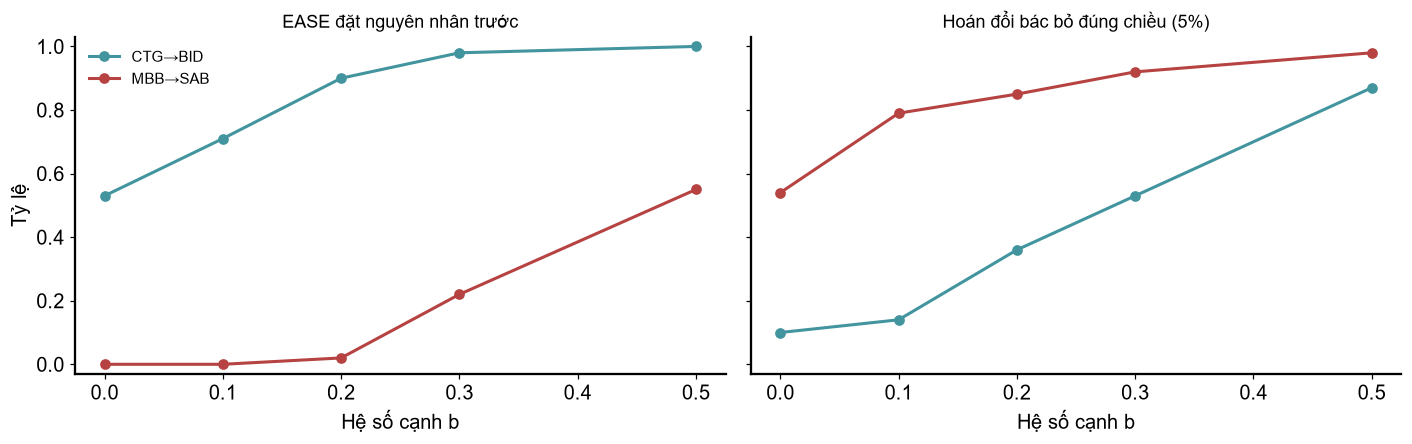

ease_dung_chieu         swap_bac_bo_dung_chieu        
canh          CTG→BID MBB→SAB                CTG→BID MBB→SAB
b                                                           
0.000           0.530   0.000                  0.100   0.540
0.100           0.710   0.000                  0.140   0.790
0.200           0.900   0.020                  0.360   0.850
0.300           0.980   0.220                  0.530   0.920
0.500           1.000   0.550                  0.870   0.980

In [6]:
power = read("04_power", index_col=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (col, title) in zip(axes, [("ease_dung_chieu", "EASE đặt nguyên nhân trước"), ("swap_bac_bo_dung_chieu", "Hoán đổi bác bỏ đúng chiều (5%)")]):
    for edge, colr in zip(power.index.get_level_values(0).unique(), [PAL["teal"], PAL["red_strong"]]):
        g = power.loc[edge, col]; ax.plot(g.index, g.values, "o-", color=colr, lw=2, label=edge)
    ax.set_xlabel("Hệ số cạnh b"); ax.set_title(title, fontsize=12); ax.set_ylim(-0.03, 1.03)
axes[0].set_ylabel("Tỷ lệ"); axes[0].legend(fontsize=10)
U.finalize_figure(fig, "finding_5_power", folder=FOLDER); plt.show()
power.unstack(0).round(2)

### Phân tích
- Hai mã tải gần nhau (CTG → BID): EASE phát hiện từ $b \approx 0{,}2$–0,3. Từ mã tải cao sang mã tải thấp (MBB → SAB): gần như không phát hiện được, và kiểm định hoán đổi
  **bác bỏ sai 54%** khi không có cạnh nào — chênh lệch tải tự tạo bất đối xứng.

## Kết luận Validation
Thứ tự EASE trên dữ liệu thô là **thứ tự độ nhạy với thị trường** (ρ = 0,91), không phải chuỗi lan truyền. Phụ thuộc đuôi giữa các mã phần lớn do thị trường; phần còn lại
nằm trong cùng ngành. Bước tiếp theo (Calibration): khử nhân tố trước EASE, chọn lại siêu tham số, và dùng thông tin **thời gian** (Granger trong đuôi).